# Proximal Policy Optimisation

PPO reuses a batch of recent CartPole transitions. Clipping the probability ratio limits the incentive to move the policy too far from the one that collected the batch.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Actor and critic updates

The shared rollout routine computes generalised advantages with discount 0.99 and trace parameter 0.95. Environment termination and time-limit truncation are handled separately.

In [2]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.distributions import Categorical
from gallery.cartpole import ActorCritic, cart_report, train_on_policy
from gallery.neural import seed_cpu


def update(net, opt, batch):
    states, actions, old_logp, adv, returns = batch
    adv = (adv - adv.mean()) / (adv.std() + 1e-6)
    for epoch in range(4):
        for ids in torch.randperm(len(states)).split(64):
            logits, values = net(states[ids])
            dist = Categorical(logits=logits)
            ratio = (dist.log_prob(actions[ids]) - old_logp[ids]).exp()
            raw = ratio * adv[ids]
            clipped = ratio.clamp(0.8, 1.2) * adv[ids]
            actor = -torch.minimum(raw, clipped).mean()
            critic = nn.functional.mse_loss(values, returns[ids])
            loss = actor + 0.45 * critic - 0.01 * dist.entropy().mean()
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 0.7)
            opt.step()

## Score the trained policy

Each seed uses 76 rollouts of 32 steps in eight environments, totalling 19,456 training transitions.

Uniform-action mean return 29.8; SD 17.0


Seed 17: mean return 184.6, median 184.5, SD 2.6, 500-step fraction 0.0%


Seed 29: mean return 136.6, median 137.0, SD 5.8, 500-step fraction 0.0%


Seed 53: mean return 137.3, median 138.0, SD 6.4, 500-step fraction 0.0%
Across training seeds: mean 152.8, sample SD 27.5


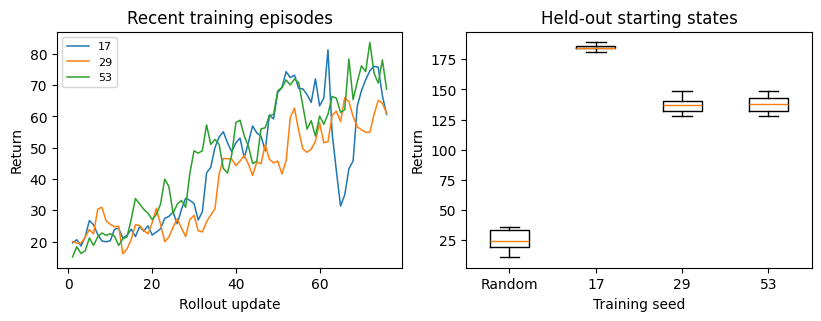

In [3]:
def train(seed):
    return train_on_policy(seed, update)


cart_report(train, "Rollout update")
plt.show()

## Reading the result

Return is capped at 500. The fraction reaching that cap distinguishes consistently long episodes from a high mean produced by a few runs.

## References

[Schulman et al., Proximal Policy Optimization Algorithms (2017)](https://arxiv.org/abs/1707.06347)

[Schulman et al., High-Dimensional Continuous Control Using Generalized Advantage Estimation](https://arxiv.org/abs/1506.02438)

[Farama Foundation, Gymnasium CartPole-v1](https://gymnasium.farama.org/environments/classic_control/cart_pole/)

[CartPole rollouts and evaluation](../../../gallery/cartpole.py)